# Лабораторная работа 7. Разработка нейрона на PyTorch

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import Linear, Sigmoid
from sklearn.metrics import accuracy_score, confusion_matrix

print("PyTorch:", torch.__version__)
print("CUDA доступна:", torch.cuda.is_available())

PyTorch: 2.10.0+cpu
CUDA доступна: False


## Учебная задача. Яблоки и груши

In [2]:
data = pd.read_csv("datasets/apples_pears/apples_pears.csv")

print("Размер набора:", data.shape)
print(data["target"].value_counts())
data.head()

Размер набора: (1000, 3)
target
1.0    588
0.0    412
Name: count, dtype: int64


,yellowness,symmetry,target
0,0.779427,0.257305,1.0
1,0.777005,0.015915,1.0
2,0.977092,0.304210,1.0
3,0.043032,0.140899,0.0
4,0.760433,0.193123,1.0


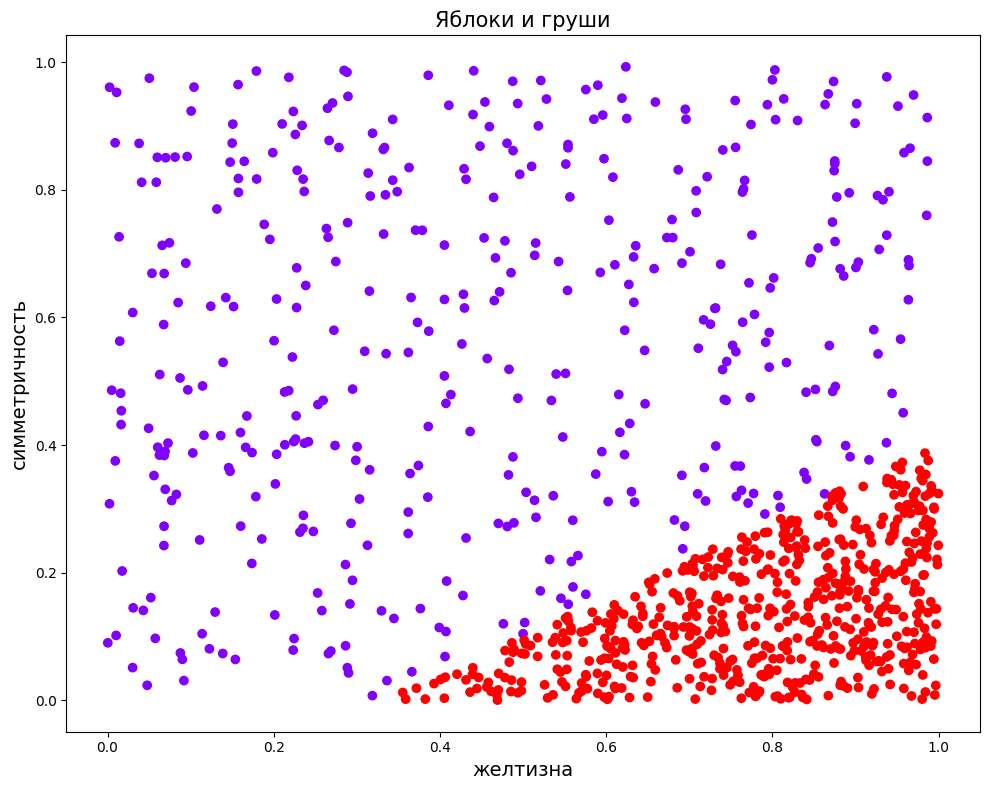

In [3]:
plt.figure(figsize=(10, 8))
plt.scatter(data.iloc[:, 0], data.iloc[:, 1], c=data["target"], cmap="rainbow")
plt.title("Яблоки и груши", fontsize=15)
plt.xlabel("желтизна", fontsize=14)
plt.ylabel("симметричность", fontsize=14)
plt.tight_layout()
plt.savefig("figures/fig01_apples_data.png", dpi=150, bbox_inches="tight")
plt.show()

In [4]:
X = data.iloc[:, :2].values
y = data["target"].values.reshape(-1, 1)

num_features = X.shape[1]

X_var = torch.autograd.Variable(torch.tensor(X, dtype=torch.float32))
y_var = torch.autograd.Variable(torch.tensor(y, dtype=torch.float32))

In [5]:
torch.manual_seed(0)

neuron = nn.Sequential(
    Linear(num_features, out_features=1),
    Sigmoid()
)
neuron

Sequential(
  (0): Linear(in_features=2, out_features=1, bias=True)
  (1): Sigmoid()
)

In [6]:
neuron(torch.autograd.Variable(torch.tensor([1.0, 1.0])))

tensor([0.4482], grad_fn=<SigmoidBackward0>)

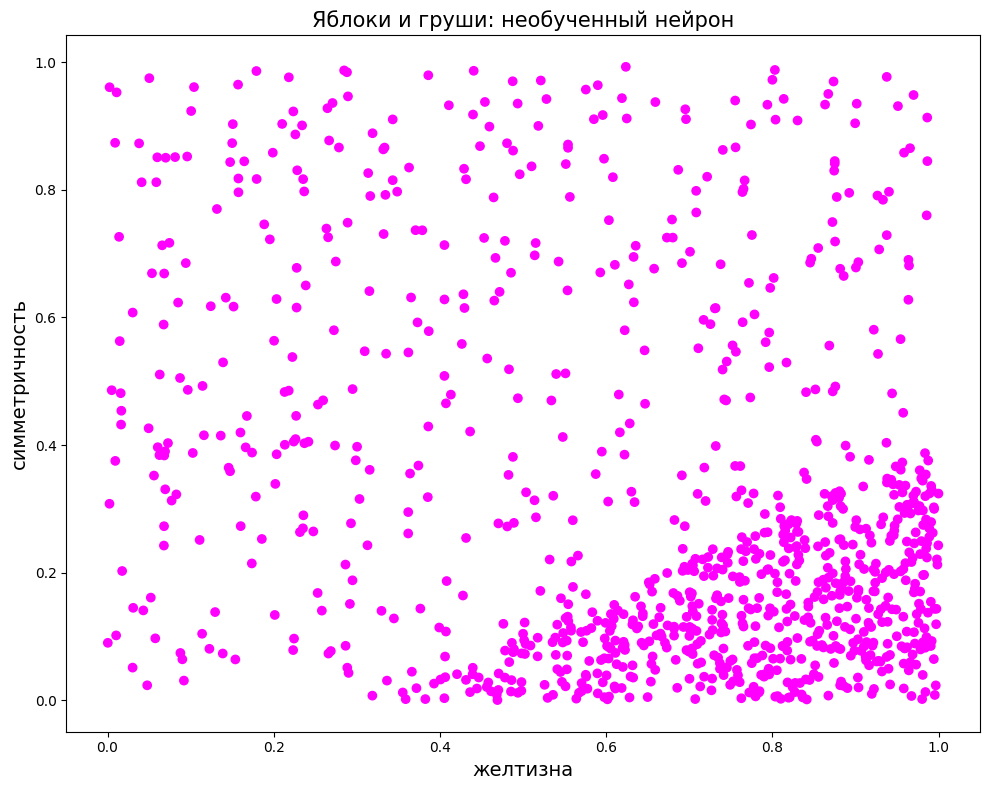

In [7]:
proba_pred = neuron(X_var)
y_pred = (proba_pred > 0.5).numpy().reshape(-1)

plt.figure(figsize=(10, 8))
plt.scatter(data.iloc[:, 0], data.iloc[:, 1], c=y_pred, cmap="spring")
plt.title("Яблоки и груши: необученный нейрон", fontsize=15)
plt.xlabel("желтизна", fontsize=14)
plt.ylabel("симметричность", fontsize=14)
plt.tight_layout()
plt.savefig("figures/fig02_apples_untrained.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
# квадратичная функция потерь
loss_fn = nn.MSELoss(reduction="sum")

# шаг градиентного спуска
learning_rate = 0.001
optimizer = torch.optim.SGD(neuron.parameters(), lr=learning_rate)

for t in range(500):
    y_pred = neuron(X_var)
    loss = loss_fn(y_pred, y_var)

    if t % 100 == 0:
        print(t, round(loss.item(), 4))

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

print("Итоговый loss:", round(loss.item(), 4))

0 302.6722
100 98.0913
200 72.2223
300 61.1837
400 54.7134
Итоговый loss: 50.3577


Accuracy: 0.952
Матрица ошибок:
 [[364  48]
 [  0 588]]


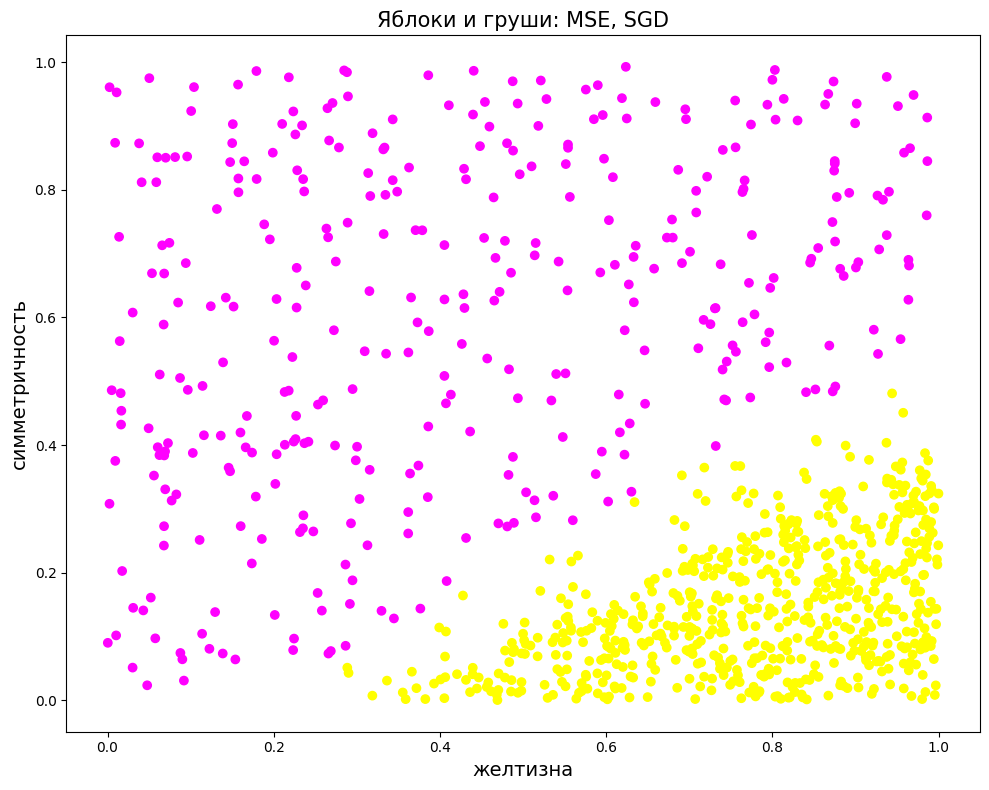

In [9]:
proba_pred = neuron(X_var)
y_pred = (proba_pred > 0.5).numpy().reshape(-1)

acc_mse = accuracy_score(y.ravel(), y_pred)
print("Accuracy:", round(acc_mse, 4))
print("Матрица ошибок:\n", confusion_matrix(y.ravel(), y_pred))

plt.figure(figsize=(10, 8))
plt.scatter(data.iloc[:, 0], data.iloc[:, 1], c=y_pred, cmap="spring")
plt.title("Яблоки и груши: MSE, SGD", fontsize=15)
plt.xlabel("желтизна", fontsize=14)
plt.ylabel("симметричность", fontsize=14)
plt.tight_layout()
plt.savefig("figures/fig03_apples_mse.png", dpi=150, bbox_inches="tight")
plt.show()

### Улучшение качества: CrossEntropyLoss

In [10]:
torch.manual_seed(42)

neuron_ce = nn.Sequential(
    Linear(num_features, out_features=2)
)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(neuron_ce.parameters(), lr=0.5)

X_ce = torch.tensor(X, dtype=torch.float32)
y_ce = torch.tensor(y.ravel(), dtype=torch.long)

losses = []
for t in range(10000):
    logits = neuron_ce(X_ce)
    loss = loss_fn(logits, y_ce)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

print("loss в начале:", round(losses[0], 4))
print("loss в конце:", round(losses[-1], 4))

loss в начале: 0.7761
loss в конце: 0.0019


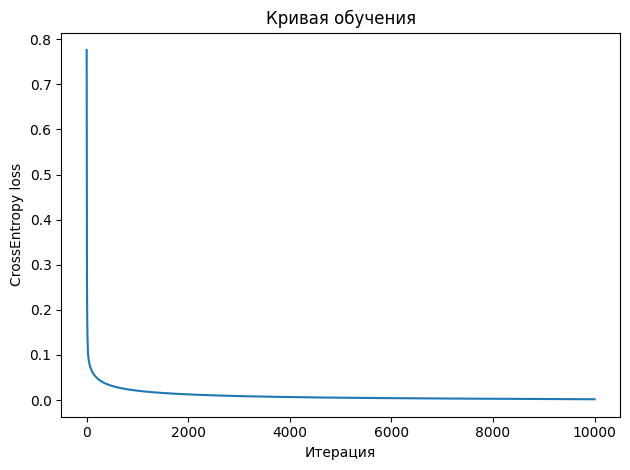

In [11]:
plt.plot(losses)
plt.xlabel("Итерация")
plt.ylabel("CrossEntropy loss")
plt.title("Кривая обучения")
plt.tight_layout()
plt.savefig("figures/fig04_apples_loss.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
with torch.no_grad():
    logits = neuron_ce(X_ce)
    y_pred_ce = logits.argmax(dim=1).numpy()

acc_ce = accuracy_score(y.ravel(), y_pred_ce)
print("Accuracy:", round(acc_ce, 4))
print("Матрица ошибок:\n", confusion_matrix(y.ravel(), y_pred_ce))

Accuracy: 1.0
Матрица ошибок:
 [[412   0]
 [  0 588]]


In [13]:
def plot_boundary(model, X, y, title, filename, mean=None, std=None,
                  xlabel="x", ylabel="y", cmap="rainbow"):
    x_min, x_max = X[:, 0].min() - 0.2, X[:, 0].max() + 0.2
    y_min, y_max = X[:, 1].min() - 0.2, X[:, 1].max() + 0.2
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))
    grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)
    if mean is not None:
        grid = (grid - mean) / std

    with torch.no_grad():
        zz = model(grid).argmax(dim=1).numpy().reshape(xx.shape)

    plt.figure(figsize=(10, 8))
    plt.contourf(xx, yy, zz, alpha=0.3, cmap=cmap)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap, edgecolor="k", linewidth=0.3)
    plt.title(title, fontsize=15)
    plt.xlabel(xlabel, fontsize=14)
    plt.ylabel(ylabel, fontsize=14)
    plt.tight_layout()
    plt.savefig(filename, dpi=150, bbox_inches="tight")
    plt.show()

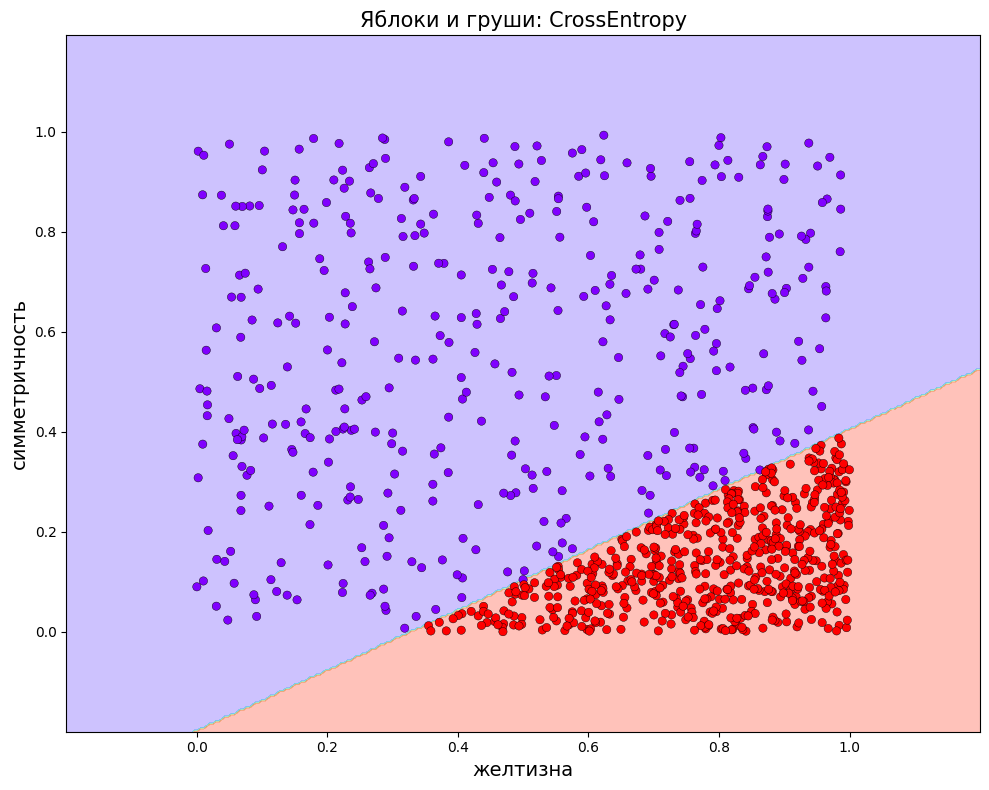

In [14]:
plot_boundary(neuron_ce, X, y.ravel(), "Яблоки и груши: CrossEntropy",
              "figures/fig05_apples_ce_boundary.png",
              xlabel="желтизна", ylabel="симметричность")

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y.ravel(), test_size=0.3, random_state=42, stratify=y)

torch.manual_seed(42)
model_holdout = nn.Sequential(Linear(num_features, out_features=2))
optimizer = torch.optim.Adam(model_holdout.parameters(), lr=0.5)
loss_fn = nn.CrossEntropyLoss()

X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.long)

for t in range(10000):
    loss = loss_fn(model_holdout(X_train_t), y_train_t)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

with torch.no_grad():
    pred_test = model_holdout(torch.tensor(X_test, dtype=torch.float32)).argmax(1).numpy()

print("Accuracy на отложенной выборке:", round(accuracy_score(y_test, pred_test), 4))

Accuracy на отложенной выборке: 0.9967


## Индивидуальное задание. Игрушка дьявола

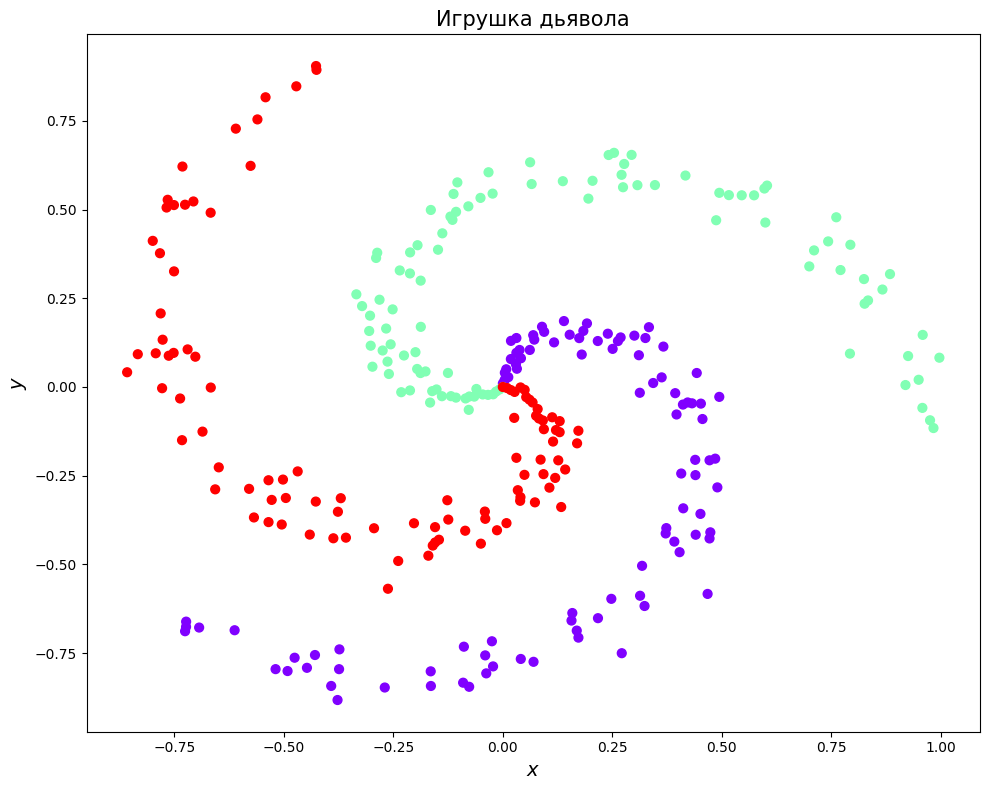

In [16]:
np.random.seed(42)

N = 100
D = 2
K = 3
X_spiral = np.zeros((N * K, D))
y_spiral = np.zeros(N * K, dtype="uint8")

for j in range(K):
    ix = range(N * j, N * (j + 1))
    r = np.linspace(0.0, 1, N)
    t = np.linspace(j * 4, (j + 1) * 4, N) + np.random.randn(N) * 0.2
    X_spiral[ix] = np.c_[r * np.sin(t), r * np.cos(t)]
    y_spiral[ix] = j

plt.figure(figsize=(10, 8))
plt.scatter(X_spiral[:, 0], X_spiral[:, 1], c=y_spiral, s=40, cmap=plt.cm.rainbow)
plt.title("Игрушка дьявола", fontsize=15)
plt.xlabel("$x$", fontsize=14)
plt.ylabel("$y$", fontsize=14)
plt.tight_layout()
plt.savefig("figures/fig06_spiral_data.png", dpi=150, bbox_inches="tight")
plt.show()

In [17]:
X_sp = torch.tensor(X_spiral, dtype=torch.float32)
y_sp = torch.tensor(y_spiral, dtype=torch.long)

torch.manual_seed(0)
spiral_neuron = nn.Sequential(
    Linear(D, out_features=K),
    nn.LogSoftmax(dim=1)
)

loss_fn = nn.NLLLoss()
optimizer = torch.optim.SGD(spiral_neuron.parameters(), lr=0.001)

for t in range(500):
    proba = spiral_neuron(X_sp)
    loss = loss_fn(proba, y_sp)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

with torch.no_grad():
    pred_spiral = spiral_neuron(X_sp).argmax(dim=1).numpy()

acc_spiral_base = accuracy_score(y_spiral, pred_spiral)
print("Accuracy:", round(acc_spiral_base, 4))
print("Матрица ошибок:\n", confusion_matrix(y_spiral, pred_spiral))

Accuracy: 0.2
Матрица ошибок:
 [[  0 100   0]
 [ 40  60   0]
 [  0 100   0]]


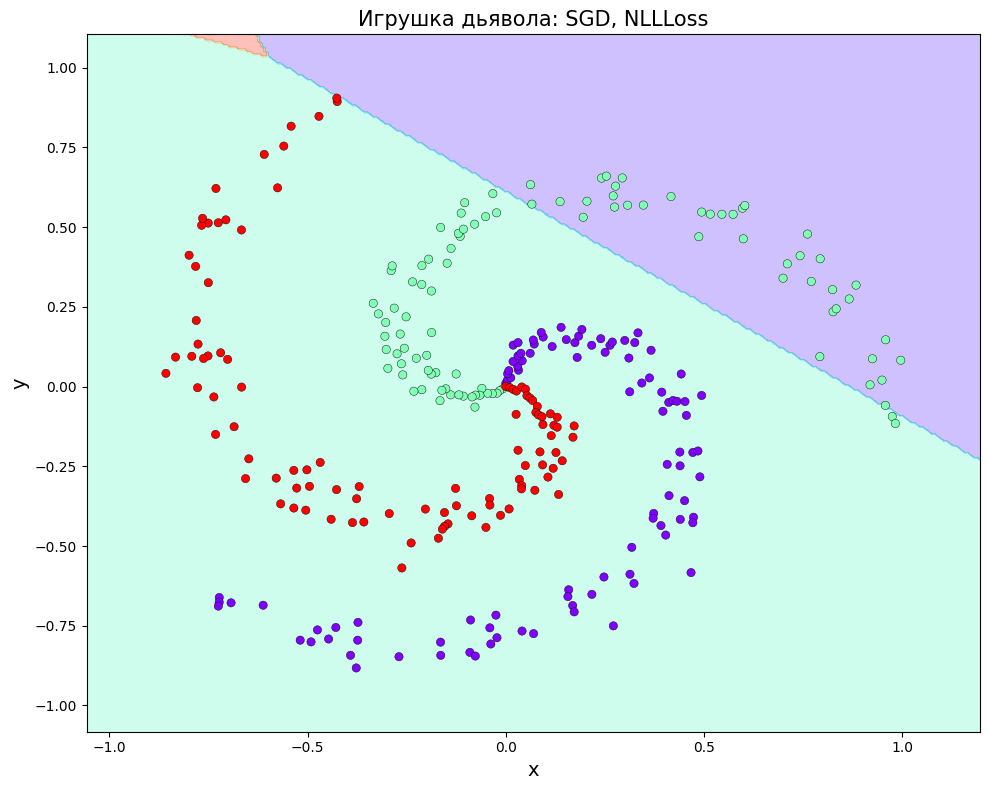

In [18]:
plot_boundary(spiral_neuron, X_spiral, y_spiral, "Игрушка дьявола: SGD, NLLLoss",
              "figures/fig07_spiral_baseline.png")

In [19]:
mean = X_sp.mean(dim=0, keepdim=True)
std = X_sp.std(dim=0, keepdim=True)
X_sp_norm = (X_sp - mean) / std

torch.manual_seed(0)
spiral_neuron_best = nn.Sequential(
    Linear(D, out_features=K)
)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(spiral_neuron_best.parameters(), lr=0.05)

losses = []
for t in range(3000):
    logits = spiral_neuron_best(X_sp_norm)
    loss = loss_fn(logits, y_sp)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

with torch.no_grad():
    pred_spiral_best = spiral_neuron_best(X_sp_norm).argmax(dim=1).numpy()

acc_spiral_best = accuracy_score(y_spiral, pred_spiral_best)
print("Accuracy:", round(acc_spiral_best, 4))
print("Матрица ошибок:\n", confusion_matrix(y_spiral, pred_spiral_best))

Accuracy: 0.5167
Матрица ошибок:
 [[53 36 11]
 [ 5 56 39]
 [47  7 46]]


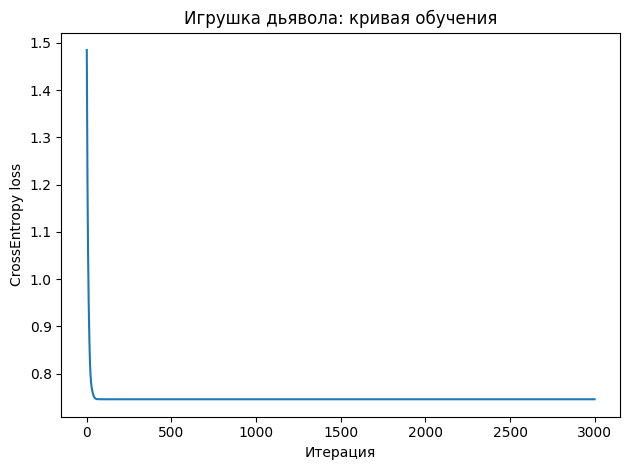

In [20]:
plt.plot(losses)
plt.xlabel("Итерация")
plt.ylabel("CrossEntropy loss")
plt.title("Игрушка дьявола: кривая обучения")
plt.tight_layout()
plt.savefig("figures/fig08_spiral_loss.png", dpi=150, bbox_inches="tight")
plt.show()

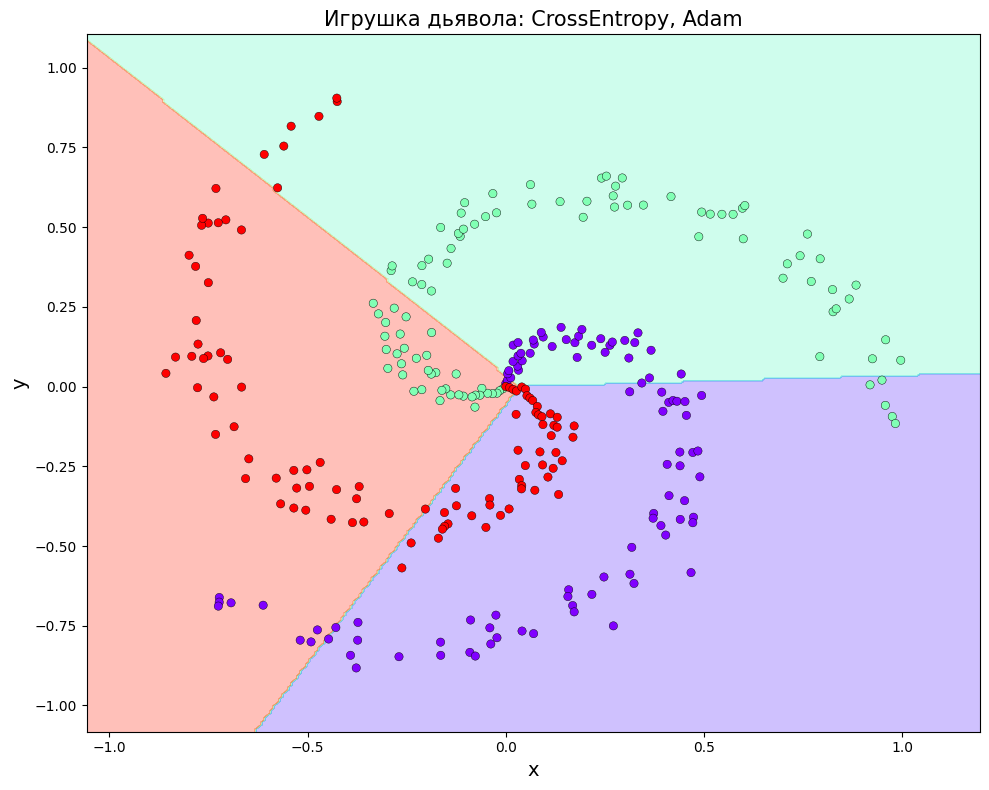

In [21]:
plot_boundary(spiral_neuron_best, X_spiral, y_spiral,
              "Игрушка дьявола: CrossEntropy, Adam",
              "figures/fig09_spiral_best.png",
              mean=mean, std=std)

In [22]:
experiments = []
loss_fn = nn.CrossEntropyLoss()

for opt_name in ["SGD", "Adam"]:
    for lr in [0.01, 0.05, 0.1]:
        torch.manual_seed(0)
        model = nn.Sequential(Linear(D, out_features=K))
        if opt_name == "SGD":
            opt = torch.optim.SGD(model.parameters(), lr=lr)
        else:
            opt = torch.optim.Adam(model.parameters(), lr=lr)

        for t in range(3000):
            loss = loss_fn(model(X_sp_norm), y_sp)
            opt.zero_grad()
            loss.backward()
            opt.step()

        with torch.no_grad():
            pred = model(X_sp_norm).argmax(dim=1).numpy()
        experiments.append((opt_name, lr, accuracy_score(y_spiral, pred)))

pd.DataFrame(experiments, columns=["Оптимизатор", "lr", "Accuracy"])

,Оптимизатор,lr,Accuracy
0,SGD,0.01,0.513333
1,SGD,0.05,0.516667
2,SGD,0.10,0.516667
3,Adam,0.01,0.516667
4,Adam,0.05,0.516667
5,Adam,0.10,0.516667


In [23]:
results = pd.DataFrame({
    "Набор": ["Яблоки и груши", "Яблоки и груши", "Игрушка дьявола", "Игрушка дьявола"],
    "Модель": ["MSE, SGD, lr=0.001, 500",
               "CrossEntropy, Adam, lr=0.5, 10000",
               "NLLLoss, SGD, lr=0.001, 500",
               "CrossEntropy, Adam, lr=0.05, 3000"],
    "Accuracy": [acc_mse, acc_ce, acc_spiral_base, acc_spiral_best],
})
results

,Набор,Модель,Accuracy
0,Яблоки и груши,"MSE, SGD, lr=0.001, 500",0.952000
1,Яблоки и груши,"CrossEntropy, Adam, lr=0.5, 10000",1.000000
2,Игрушка дьявола,"NLLLoss, SGD, lr=0.001, 500",0.200000
3,Игрушка дьявола,"CrossEntropy, Adam, lr=0.05, 3000",0.516667
